## Step 0 — Setup: import the libraries we need

In [ ]:
import os, itertools, warnings                 # os: file tools | itertools: helps try many setting combinations | warnings: hide noisy messages
import numpy as np                             # numpy: fast maths on lists/tables of numbers (we call it "np")
import pandas as pd                            # pandas: tables (DataFrames) (we call it "pd")
import matplotlib.pyplot as plt                # matplotlib: draws charts (we call it "plt")
import seaborn as sns                          # seaborn: makes charts look nicer

from sklearn.feature_extraction.text import TfidfVectorizer   # turns review TEXT into numbers (TF-IDF, as in the paper)
from sklearn.preprocessing import MinMaxScaler                # rescales numbers to the range 0..1
from sklearn.metrics.pairwise import cosine_similarity        # measures how similar two rows of numbers are
from sklearn.tree import DecisionTreeClassifier               # the decision tree used in paper section 3.4
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score   # the paper's evaluation metrics

warnings.filterwarnings('ignore')              # hide harmless warning messages so the output stays clean
sns.set_style('whitegrid')                     # chart style: light grid background
pd.set_option('display.max_columns', None)     # show ALL columns when printing a table
SEED = 42                                      # fixed random seed -> the notebook gives the SAME results every run
print('Libraries loaded.')

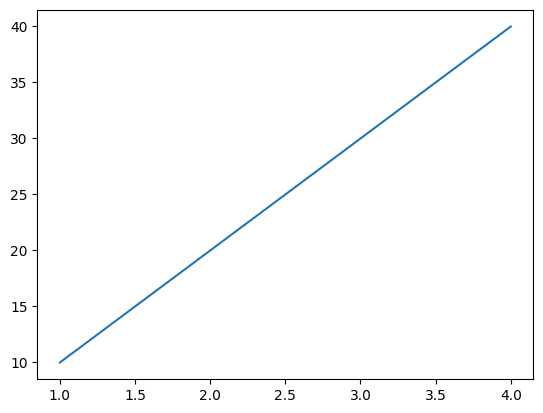

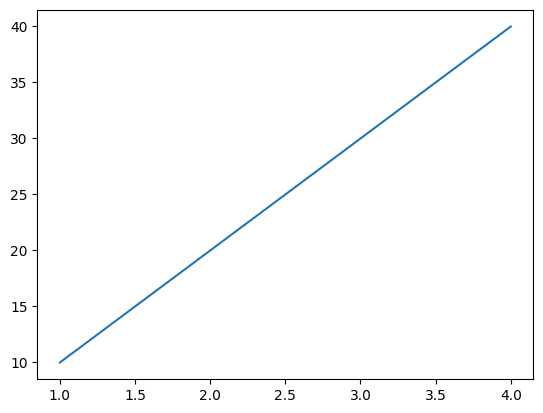

In [1]:
import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [10, 20, 30, 40]

plt.plot(x, y)
plt.show()
import seaborn as sns

x = [1, 2, 3, 4]
y = [10, 20, 30, 40]

sns.lineplot(x=x, y=y)
plt.show()

## Step 1 — Generate the synthetic dataset

The real TripAdvisor data is not available, so we simulate it. A synthetic dataset is only useful if it contains **learnable structure**, so every rating is generated from explicit, explainable causes:

| Ingredient | How it is simulated | Why |
|---|---|---|
| Attraction category | 6 categories from the paper; probability depends on the city type (heritage / urban / mountain / coast) | so *location* and *category* are correlated, as in real life |
| Attraction quality | hidden score ~ N(0, 0.45) | some places are simply better |
| User favourite categories | each user has 1–2 favourites | drives **personalisation** (what CF/CB/KB must discover) |
| User generosity | bias ~ N(0, 0.35) | some users rate high, some rate low |
| Which places a user rates | favourites are 3× more likely to be visited | people visit what they like |
| Rating | `2.9 + 0.8·[favourite] + 0.8·quality + bias + noise(0.65)`, rounded to 1–5 | the ground-truth rule |
| Registration form | the user's *stated* preferences equal their favourites, but each is wrong 15 % of the time | this is the input the **KB module** uses (paper §3.2.3 / §6) |
| Review text | sentiment matches the rating only 75 % of the time + a category-specific sentence | **not** a copy of the rating (no leakage) |

The 11 original columns of the paper's dataset are kept, plus `user_stated_preferences`.

In [2]:
import numpy as np, pandas as pd

def generate_dataset(seed=42, n_users=1791, n_ratings=9640, n_items=88):
    """Builds a fake-but-realistic tourism ratings table.
    A 'function' is a reusable block of code: you give it settings (seed, number of users...)
    and it returns a finished table (called a DataFrame)."""

    # The 'seed' makes the random numbers repeatable: same seed -> exactly the same dataset every run.
    rng = np.random.default_rng(seed)

    # The 6 attraction categories used in the paper
    CATS = ['Historical Landmark', 'Museum', 'Natural Wonder',
            'Adventure Spot', 'Urban Landmark', 'Entertainment Venue']

    # 20 real Pakistani cities with their true GPS position (latitude, longitude)
    # and a "type" that decides what kind of attractions are likely to be found there.
    CITIES = {
        'Lahore': (31.55, 74.34, 'heritage'), 'Multan': (30.16, 71.52, 'heritage'),
        'Taxila': (33.74, 72.79, 'heritage'), 'Peshawar': (34.01, 71.58, 'heritage'),
        'Bahawalpur': (29.40, 71.68, 'heritage'), 'Rawalpindi': (33.60, 73.04, 'heritage'),
        'Islamabad': (33.68, 73.05, 'urban'), 'Karachi': (24.86, 67.01, 'urban'),
        'Faisalabad': (31.42, 73.08, 'urban'), 'Sialkot': (32.49, 74.53, 'urban'),
        'Quetta': (30.18, 66.99, 'urban'),
        'Hunza': (36.32, 74.65, 'mountain'), 'Skardu': (35.30, 75.63, 'mountain'),
        'Gilgit': (35.92, 74.31, 'mountain'), 'Naran': (34.91, 73.65, 'mountain'),
        'Chitral': (35.85, 71.79, 'mountain'), 'Swat': (35.22, 72.43, 'mountain'),
        'Murree': (33.91, 73.39, 'mountain'), 'Nathia Gali': (34.07, 73.38, 'mountain'),
        'Gwadar': (25.12, 62.32, 'coast'),
    }

    # For each city type: the chance of each of the 6 categories (same order as CATS; each row adds up to 1).
    # Example: a 'mountain' city is 43% likely to get a Natural Wonder and 40% an Adventure Spot.
    cat_w = {
        'heritage': [.40, .30, .05, .05, .10, .10],
        'urban':    [.10, .15, .05, .05, .35, .30],
        'mountain': [.05, .02, .43, .40, .05, .05],
        'coast':    [.05, .05, .35, .25, .10, .20],
    }
    city_names = list(CITIES)

    # ---------------------------------------------------------------- 1) ATTRACTIONS (88)
    # Spread the 88 attractions as evenly as possible over the 20 cities (4 or 5 per city).
    per_city = np.full(len(city_names), n_items // len(city_names))
    per_city[: n_items - per_city.sum()] += 1
    rows = []
    for c, k in zip(city_names, per_city):            # loop over every city and how many attractions it gets
        lat, lon, typ = CITIES[c]
        for _ in range(k):                            # create k attractions in this city
            cat = rng.choice(CATS, p=cat_w[typ])      # pick a category using this city type's probabilities
            rows.append(dict(location_name=c, preferred_category=cat,
                             latitude=lat + rng.normal(0, .06),      # small random shift so attractions
                             longitude=lon + rng.normal(0, .06)))    # in one city are not at the same point
    items = pd.DataFrame(rows)
    items['attraction_id'] = [f'A{i+1:03d}' for i in range(n_items)]                    # A001 ... A088
    items['hotel_name'] = [f'{c} Grand Hotel {rng.integers(1, 4)}' for c in items.location_name]
    items['quality'] = rng.normal(0, .45, n_items)         # HIDDEN true quality: some places are just better
    items['popularity'] = rng.lognormal(0, .35, n_items)   # HIDDEN popularity: some places get more visitors

    # ---------------------------------------------------------------- 2) USERS (1791)
    users = pd.DataFrame({'user_id': [f'U{i+1:04d}' for i in range(n_users)]})     # U0001 ... U1791
    users['name'] = ['User ' + u[1:] for u in users.user_id]
    users['bias'] = rng.normal(0, .35, n_users)            # HIDDEN generosity: some users rate high, some low
    favs, stated = [], []
    for _ in range(n_users):
        # each user truly loves 1 category (55% of users) or 2 categories (45% of users)
        f = list(rng.choice(CATS, size=rng.choice([1, 2], p=[.55, .45]), replace=False))
        favs.append(f)
        # What the user TYPES on the registration form: their real favourites, but each answer is
        # replaced by a random category 15% of the time (people are not perfectly accurate).
        s = [x if rng.random() > .15 else rng.choice(CATS) for x in f]
        stated.append('|'.join(sorted(set(s))))            # store as text, e.g. "Museum|Natural Wonder"
    users['favs'] = favs
    users['stated_preferences'] = stated

    # ---------------------------------------------------------------- 3) HOW MANY RATINGS EACH USER GIVES
    # Every user gives at least 1 rating; on average about 5.4. We then nudge random users up or down
    # until the grand total is EXACTLY 9640 (the same as the paper).
    deg = 1 + rng.poisson((n_ratings - n_users) / n_users, n_users)
    deg = np.minimum(deg, n_items)
    while deg.sum() != n_ratings:
        j = rng.integers(0, n_users)
        if deg.sum() > n_ratings and deg[j] > 1: deg[j] -= 1
        elif deg.sum() < n_ratings and deg[j] < 14: deg[j] += 1

    # ---------------------------------------------------------------- 4) REVIEW TEXT
    # Sentence pieces. A review = [opening sentence matching the mood] + [sentence about the category] + [city].
    OPEN = {
        'neg': ["Not a great experience overall.", "I was quite disappointed.", "It did not live up to the hype.",
                "Would not recommend this place.", "Poor value for the time spent."],
        'neu': ["It was an average visit.", "A decent place, nothing extraordinary.", "Okay experience overall.",
                "Some good points and some bad ones.", "Fine for a short stop."],
        'pos': ["Absolutely loved this place!", "A wonderful and memorable visit.", "Highly recommended to every traveller.",
                "One of the best stops of my trip.", "Great experience, worth every minute."],
    }
    TOPIC = {
        'Historical Landmark': ["The old fort walls and heritage architecture tell a rich story.",
                                "Ancient ruins and centuries of history everywhere.",
                                "The guide explained the dynasty and the historic monuments well."],
        'Museum': ["The exhibits and gallery collections were well organised.",
                   "Artifacts, paintings and displays covered local culture nicely.",
                   "The curators arranged the museum halls thoughtfully."],
        'Natural Wonder': ["The valley, lake and mountain scenery were breathtaking.",
                           "Waterfalls and forests made for stunning nature views.",
                           "Clean air, rivers and peaceful natural beauty."],
        'Adventure Spot': ["The trekking trail and zip-line were thrilling.",
                           "Great hiking, camping and climbing activities.",
                           "Adrenaline all day with rafting and jeep safaris."],
        'Urban Landmark': ["The city square, towers and modern architecture are impressive.",
                           "Busy markets, streets and skyline views downtown.",
                           "A lively urban landmark with cafes all around."],
        'Entertainment Venue': ["The theme park rides and live shows were fun for the family.",
                                "Concerts, cinema and amusement games for all ages.",
                                "Great shows, food stalls and entertainment for kids."],
    }
    def review(rating, cat, city):
        s = rating
        # 25% of the time the mood of the text is one star away from the rating, so the review
        # is NOT a perfect copy of the rating (a perfect copy would be "data leakage" = cheating).
        if rng.random() < .25: s = int(np.clip(rating + rng.choice([-1, 1]), 1, 5))
        b = 'neg' if s <= 2 else 'neu' if s == 3 else 'pos'      # 1-2 stars = negative, 3 = neutral, 4-5 = positive
        return f"{rng.choice(OPEN[b])} {rng.choice(TOPIC[cat])} Visited {city}."

    # ---------------------------------------------------------------- 5) GENERATE EVERY RATING
    it_cat = items.preferred_category.values
    out = []
    for ui, u in users.iterrows():                      # go through users one by one
        # People visit what they like: attractions in the user's favourite categories are 3x more likely to be chosen.
        match_bonus = np.where(np.isin(it_cat, u.favs), 3.0, 1.0)
        p = items.popularity.values * match_bonus       # chance of visiting = popularity x bonus
        p = p / p.sum()                                 # turn into proper probabilities that add up to 1
        chosen = rng.choice(n_items, size=deg[ui], replace=False, p=p)   # which attractions this user rated
        for ii in chosen:
            it = items.iloc[ii]
            match = float(it.preferred_category in u.favs)   # 1 if this is one of the user's favourite categories
            # THE RATING RULE (the "hidden truth" the recommender must discover):
            #   base 2.9  + 0.8 if it is a favourite category  + 0.8 x attraction quality
            #   + the user's own generosity + a bit of random noise
            latent = 2.9 + .8 * match + .8 * it.quality + u.bias + rng.normal(0, .65)
            r = int(np.clip(np.round(latent), 1, 5))         # round to a whole number between 1 and 5 stars
            out.append(dict(user_id=u.user_id, name=u['name'], attraction_id=it.attraction_id,
                            hotel_name=it.hotel_name, rating=r, location_name=it.location_name,
                            preferred_category=it.preferred_category,
                            latitude=round(it.latitude, 6), longitude=round(it.longitude, 6),
                            review=review(r, it.preferred_category, it.location_name),
                            # random date between 1 Jan 2023 and 31 Dec 2025
                            timestamp=str(pd.Timestamp('2023-01-01') + pd.Timedelta(days=int(rng.integers(0, 1095)))).split()[0],
                            user_stated_preferences=u.stated_preferences))
    # shuffle the rows so they are not ordered by user, then return the finished table
    df = pd.DataFrame(out).sample(frac=1, random_state=seed).reset_index(drop=True)
    return df

In [6]:
SEED = 42                                              # ensure SEED is defined in this cell context
df_raw = generate_dataset(seed=SEED)                   # call the function defined above -> returns the full table
df_raw.to_csv('tourism_dataset_v2.csv', index=False)   # save it as a CSV file next to this notebook
print('Saved tourism_dataset_v2.csv', df_raw.shape)    # .shape = (number of rows, number of columns)
df_raw.head()                                          # show the first 5 rows so you can see what the data looks like

Saved tourism_dataset_v2.csv (9640, 12)


,user_id,name,attraction_id,hotel_name,rating,location_name,preferred_category,latitude,longitude,review,timestamp,user_stated_preferences
0,U1216,User 1216,A001,Lahore Grand Hotel 1,3,Lahore,Adventure Spot,31.487601,74.385027,Some good points and some bad ones. Great hiki...,2025-07-13,Historical Landmark
1,U0128,User 0128,A074,Swat Grand Hotel 2,4,Swat,Entertainment Venue,35.210730,72.388243,Highly recommended to every traveller. Great s...,2023-01-19,Entertainment Venue|Natural Wonder
2,U0695,User 0695,A080,Murree Grand Hotel 2,3,Murree,Adventure Spot,33.781163,73.380240,"A decent place, nothing extraordinary. Adrenal...",2024-05-03,Museum|Urban Landmark
3,U0264,User 0264,A045,Sialkot Grand Hotel 3,4,Sialkot,Urban Landmark,32.476667,74.441752,"Great experience, worth every minute. Busy mar...",2023-09-09,Museum
4,U1163,User 1163,A014,Taxila Grand Hotel 2,2,Taxila,Museum,33.784595,72.822589,Would not recommend this place. The exhibits a...,2024-08-02,Natural Wonder


## Step 2 — Load & preprocess (paper §3.1.2)

Cleaning steps from the paper: remove duplicates, drop invalid ratings (outside 1–5), drop rows missing essential fields, filter reviews shorter than 3 words.
*(The paper's min–max "normalisation" to 1–5 is a no-op here because ratings are already on that scale.)*

In [7]:
df = pd.read_csv('tourism_dataset_v2.csv')                       # read the CSV file back into a table
before = len(df)                                                 # remember how many rows we started with
df = df.drop_duplicates(subset=['user_id', 'attraction_id'])     # a user should rate an attraction only once -> remove repeats
df = df[(df.rating >= 1) & (df.rating <= 5)]                     # keep only valid star ratings (1 to 5)
df = df.dropna(subset=['user_id', 'attraction_id', 'rating'])    # drop rows where an essential field is empty
df = df[df.review.str.split().str.len() >= 3].reset_index(drop=True)   # drop reviews with fewer than 3 words (too short to be useful)
print(f'Rows before cleaning: {before}   after: {len(df)}')

# A small summary table, like Table 1 of the paper
summary = pd.DataFrame({
    'Attribute': ['Total ratings', 'Attractions', 'Users', 'Rating scale', 'Sparsity'],
    'Value': [len(df), df.attraction_id.nunique(), df.user_id.nunique(), '1–5',
              # sparsity = share of the (users x attractions) grid that is EMPTY
              f'{1 - len(df) / (df.user_id.nunique() * df.attraction_id.nunique()):.1%}']})
summary   # compare with the paper's Table 1

Rows before cleaning: 9640   after: 9640


,Attribute,Value
0,Total ratings,9640
1,Attractions,88
2,Users,1791
3,Rating scale,1–5
4,Sparsity,93.9%


### Sanity check: does the data contain real signal?
In v1 the answer was **no**. Here we verify the structure we built in — this is also good evidence to show your panel.

Std of attraction mean ratings : 0.372   (pure chance would give ≈ 0.090)
pref_match
not in stated prefs    2.996
in stated prefs        3.670


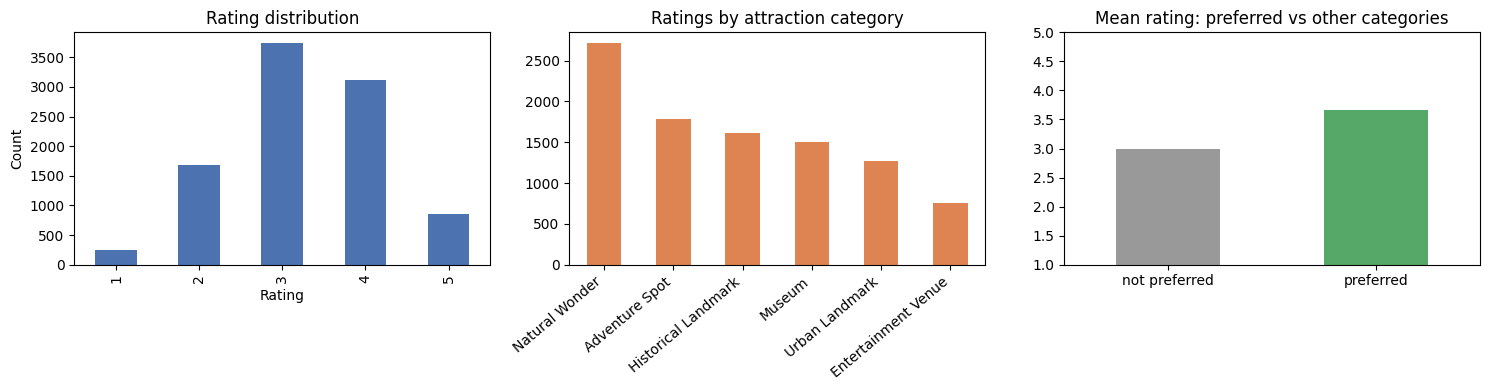

In [8]:
# For every rating: was the attraction's category one the user listed on the registration form? (True/False)
match = [c in s.split('|') for c, s in zip(df.preferred_category, df.user_stated_preferences)]
df['pref_match'] = match

# If ratings were pure random noise, all attractions would have almost the same average rating.
per_attr = df.groupby('attraction_id').rating.agg(['mean', 'size'])          # average rating and #ratings per attraction
noise_only = df.rating.std() / np.sqrt(per_attr['size'].mean())              # how much the averages would differ by pure chance
print(f"Std of attraction mean ratings : {per_attr['mean'].std():.3f}   (pure chance would give ≈ {noise_only:.3f})")
# Do users rate their preferred categories higher?
print(df.groupby('pref_match').rating.mean().round(3).rename({False: 'not in stated prefs', True: 'in stated prefs'}).to_string())

# Three charts side by side
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.rating.value_counts().sort_index().plot(kind='bar', ax=ax[0], color='#4C72B0')        # chart 1: how many 1,2,3,4,5-star ratings
ax[0].set_title('Rating distribution'); ax[0].set_xlabel('Rating'); ax[0].set_ylabel('Count')
df.preferred_category.value_counts().plot(kind='bar', ax=ax[1], color='#DD8452')         # chart 2: ratings per category
ax[1].set_title('Ratings by attraction category'); ax[1].set_xlabel('')
plt.setp(ax[1].get_xticklabels(), rotation=40, ha='right')
df.groupby('pref_match').rating.mean().rename({False: 'not preferred', True: 'preferred'}).plot(kind='bar', ax=ax[2], color=['#999999', '#55A868'])  # chart 3
ax[2].set_title('Mean rating: preferred vs other categories'); ax[2].set_ylim(1, 5); ax[2].set_xlabel('')
plt.setp(ax[2].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

## Step 3 — Index the data and prepare content features

Users and attractions become integer indices so every model can produce a full **users × attractions** prediction matrix.
Content features for an attraction (category, location) are known even for a brand-new attraction; user *stated preferences* come from the registration form.

In [9]:
users = sorted(df.user_id.unique()); items = sorted(df.attraction_id.unique())   # sorted lists of all user ids / attraction ids
uix = {u: k for k, u in enumerate(users)}; iix = {a: k for k, a in enumerate(items)}   # dictionaries: id text -> number 0,1,2,...
df['u'] = df.user_id.map(uix); df['i'] = df.attraction_id.map(iix)               # add numeric columns: u = user number, i = item number
nU, nI = len(users), len(items)                                                  # nU = number of users, nI = number of items
CATS = sorted(df.preferred_category.unique())                                    # the 6 category names

# One row per attraction with its category, city and GPS position (these never change, so 'first' is enough)
item_info = df.groupby('i').agg(cat=('preferred_category', 'first'), city=('location_name', 'first'),
                                lat=('latitude', 'first'), lon=('longitude', 'first')).reindex(range(nI))
item_cat_idx = np.array([CATS.index(c) for c in item_info.cat])                  # each attraction's category as a number 0..5

# 'stated' is a table users x categories: 1 if the user ticked that category on the registration form, else 0
stated = np.zeros((nU, len(CATS)))
for u, s in df.groupby('u').user_stated_preferences.first().items():
    for c in s.split('|'): stated[u, CATS.index(c)] = 1
# match_mat[u, i] = 1 if attraction i belongs to a category that user u said they like (used by the KB module)
match_mat = stated[:, item_cat_idx]
print(f'{nU} users × {nI} attractions | categories: {CATS}')

1791 users × 88 attractions | categories: ['Adventure Spot', 'Entertainment Venue', 'Historical Landmark', 'Museum', 'Natural Wonder', 'Urban Landmark']


## Step 4 — Train / validation / test split (with cold start!)

A plain random split almost never produces new users (only ~2 % of test users), so the paper's central claim — *the hybrid solves cold start* — would go untested. We therefore:

* hide **10 % of users completely** (all their ratings → test) ⇒ *new users*
* hide **8 attractions completely** (all their ratings → test) ⇒ *new items*
* split the remaining ratings 80 / 20 into train / test
* carve a **validation set** (15 % of train) for choosing hyper-parameters — the test set is never used for tuning

A user (item) is "known" **iff it appears in the training data**. That defines the four cases of Algorithm 1.

In [10]:
def make_split(df, cold_user_frac=.10, n_cold_items=8, test_frac=.20, seed=SEED):
    """Returns (train, test). Cold users/items are removed from training completely."""
    r = np.random.default_rng(seed)
    cold_users = set(r.choice(nU, int(cold_user_frac * nU), replace=False))   # randomly pick 10% of users to be "brand new"
    cold_items = set(r.choice(nI, n_cold_items, replace=False))               # randomly pick 8 attractions to be "brand new"
    forced = df.u.isin(cold_users) | df.i.isin(cold_items)                    # every rating touching a cold user/item -> TEST
    rest = df[~forced]                                                        # the remaining ratings
    rnd = r.random(len(rest)) < test_frac                                     # randomly mark ~20% of them for the test set
    return rest[~rnd].copy(), pd.concat([df[forced], rest[rnd]]).copy()       # (train, test)

train_full, test = make_split(df)
# From the training data, hold out 15% as a VALIDATION set (used only for choosing settings)
r_ = np.random.default_rng(SEED + 1); vmask = r_.random(len(train_full)) < .15
train_core, val = train_full[~vmask].copy(), train_full[vmask].copy()

def case_of(known_u, known_i):
    """Label each (user, item) pair with one of the 4 cases of the paper's Algorithm 1."""
    return np.where(known_u & known_i, 'i',            # case i  : known user + known item
           np.where(~known_u & known_i, 'ii',           # case ii : NEW user  + known item
           np.where(~known_u & ~known_i, 'iii', 'iv'))) # case iii: NEW user + NEW item | case iv: known user + NEW item

ku, ki = set(train_full.u), set(train_full.i)                                   # users/items that appear in training = "known"
test_cases = case_of(test.u.isin(ku).values, test.i.isin(ki).values)            # case label for every test rating
CASE_NAMES = {'i': 'known user, known item', 'ii': 'NEW user, known item', 'iii': 'NEW user, NEW item', 'iv': 'known user, NEW item'}
print(f'train {len(train_full)} (core {len(train_core)} + val {len(val)})   test {len(test)}')
pd.DataFrame({'case': list(CASE_NAMES), 'meaning': list(CASE_NAMES.values()),
              'test ratings': [int((test_cases == c).sum()) for c in CASE_NAMES]})   # how many test ratings fall in each case

train 6226 (core 5238 + val 988)   test 3414


,case,meaning,test ratings
0,i,"known user, known item",1581
1,ii,"NEW user, known item",923
2,iii,"NEW user, NEW item",119
3,iv,"known user, NEW item",791


## Step 5 — The three filtering modules (paper §3.2)

Each module produces a **full prediction matrix**; a cell is `NaN` ("not a number" = empty) when that module *cannot* predict (e.g. CF for a user it has never seen). This makes Algorithm 1 easy to implement honestly.

| Module | Idea | Needs | Implementation |
|---|---|---|---|
| **KB** (§3.2.3) | domain rules + case base | registration form only | `global mean + item quality from case base + δ·[category ∈ stated preferences]`; δ is read from the training data |
| **CF** (§3.2.4) | learn from other users' ratings | known user **and** known item | biased matrix factorisation (the paper lists matrix factorisation as its CF technique, §3.1.2 iii) |
| **CB** (§3.2.5) | similar items to what the user liked | user history (item may be **new**) | item-similarity from category + location + review TF-IDF |

*Note:* we first tried user-based k-NN for CF; with ~5 ratings per user two users almost never share a rated item, so it only covered 36 % of test pairs. Matrix factorisation copes with this sparsity much better.

In [11]:
class Modules:
    """A 'class' bundles data + functions. Creating Modules(train) trains ALL THREE recommenders on the training data
    and stores their predictions as tables of size (users x attractions): self.kb, self.cf, self.cb.
    NaN in a table means: 'this module has no basis to predict here'."""

    def __init__(self, train, cb_power=1.0, cb_lam=1.0, cb_geo=0.5, cb_tfidf=0.7,
                 mf_k=8, mf_lam=0.3, mf_epochs=40, fit_cf=True):
        self.tr, self.gm = train, train.rating.mean()          # gm = global mean rating (the "average star" over all training ratings)
        # R = big table (users x attractions) holding the known ratings; empty cells = NaN
        R = np.full((nU, nI), np.nan); R[train.u, train.i] = train.rating
        self.R, self.M = R, ~np.isnan(R)                        # M = True where a rating exists
        n_u, n_i = self.M.sum(1), self.M.sum(0)                 # number of ratings per user / per attraction
        self.known_u, self.known_i = n_u > 0, n_i > 0           # "known" = has at least 1 training rating
        # Average rating per user and per attraction. The "+2*gm / +5*gm" pulls averages based on very few ratings
        # towards the global mean, so 1 lucky rating can't make a place look perfect (called "shrinkage").
        self.um = (np.nansum(R, 1) + 2 * self.gm) / (n_u + 2)
        self.im = (np.nansum(R, 0) + 5 * self.gm) / (n_i + 5)
        self.Z = np.where(self.M, R - self.gm, 0.0)             # each rating minus the global mean (0 where no rating)
        self.cb_power, self.cb_lam, self.cb_geo, self.cb_tfidf = cb_power, cb_lam, cb_geo, cb_tfidf   # CB settings
        self.mf_k, self.mf_lam, self.mf_epochs = mf_k, mf_lam, mf_epochs                              # CF settings
        self._fit_kb(); self._fit_cb()                          # train KB and CB
        self.cf = self._fit_cf() if fit_cf else None            # train CF (slowest, so it can be skipped while tuning CB)

    # ---- KB: domain rules + case base -------------------------------------------------
    def _fit_kb(self):
        tr = self.tr
        m = match_mat[tr.u.values, tr.i.values] == 1            # for each training rating: was it in a preferred category?
        # RULE STRENGTH read from the data: how many stars higher do people rate places in categories they said they like?
        self.delta = tr.rating[m].mean() - tr.rating[~m].mean()
        item_eff = np.where(self.known_i, self.im - self.gm, 0.0)       # case base: how much better/worse than average is this place (0 if new)
        # KB prediction = average + item quality + bonus if the category matches the user's stated interests.
        # It works for EVERY user and item because it only needs the registration form.
        self.kb = self.gm + item_eff[None, :] + self.delta * match_mat

    # ---- CF: biased matrix factorisation ----------------------------------------------
    def _fit_cf(self):
        # Idea: learn a few hidden "taste numbers" for every user and every attraction, so that
        # rating ≈ average + user bias + item bias + (user tastes · item features).
        # The loop below repeatedly nudges these numbers to reduce the prediction errors (called SGD).
        r = np.random.default_rng(SEED)
        k, lam, lr = self.mf_k, self.mf_lam, 0.02              # k = number of hidden factors, lam = penalty against over-fitting, lr = step size
        U, I = self.tr.u.values, self.tr.i.values
        Y = self.tr.rating.values - self.gm                    # the ratings we learn from (minus the average)
        bu, bi = np.zeros(nU), np.zeros(nI)                    # user bias and item bias, start at 0
        P, Q = r.normal(0, .1, (nU, k)), r.normal(0, .1, (nI, k))   # hidden taste numbers, start as small random values
        for _ in range(self.mf_epochs):                        # repeat the whole training set many times ("epochs")
            for t in r.permutation(len(Y)):                    # visit the ratings in random order
                u, i = U[t], I[t]
                e = Y[t] - (bu[u] + bi[i] + P[u] @ Q[i])       # error = real rating - current guess
                bu[u] += lr * (e - lam * bu[u]); bi[i] += lr * (e - lam * bi[i])     # nudge the biases to shrink the error
                pu = P[u].copy()
                P[u] += lr * (e * Q[i] - lam * P[u]); Q[i] += lr * (e * pu - lam * Q[i])   # nudge the hidden factors
        pred = np.clip(self.gm + bu[:, None] + bi[None, :] + P @ Q.T, 1, 5)   # predictions for ALL users x items, kept within 1..5
        # CF is only allowed to answer when BOTH the user and the item were seen in training
        return np.where(self.known_u[:, None] & self.known_i[None, :], pred, np.nan)

    # ---- CB: item content similarity ---------------------------------------------------
    def _fit_cb(self):
        onehot = np.eye(len(CATS))[item_cat_idx]               # category as 6 columns of 0/1 ("one-hot encoding", as in the paper)
        geo = MinMaxScaler().fit_transform(item_info[['lat', 'lon']].values) * self.cb_geo   # location rescaled to 0..1 (times a weight)
        # All training reviews of an attraction glued into one text. A NEW attraction has no reviews -> empty text.
        docs = self.tr.groupby('i').review.apply(' '.join).reindex(range(nI)).fillna('')
        tf = TfidfVectorizer(stop_words='english', min_df=3).fit_transform(docs).toarray()   # TF-IDF: text -> numbers (paper §3.1.2 v)
        tf = tf / (np.linalg.norm(tf, axis=1, keepdims=True) + 1e-9) * self.cb_tfidf         # scale each text vector to a standard length
        # Similarity between every pair of attractions using category + location + review words (0 = unrelated, 1 = identical)
        sim = cosine_similarity(np.hstack([onehot, geo, tf])); np.fill_diagonal(sim, 0); sim[sim < 0] = 0
        W = sim ** self.cb_power
        # For attraction i and user u: look at the places u rated, weight each by how similar it is to i,
        # and average how far above/below average u rated them.
        num, den = self.Z @ W.T, self.M.astype(float) @ W.T
        pred = self.gm + num / (den + self.cb_lam)
        # CB needs the user's history (den > 0) but the attraction itself may be NEW (only its category/location is used)
        self.cb = np.where(self.known_u[:, None] & (den > 0), pred, np.nan)
        self.item_sim = sim

    def module(self, name): return getattr(self, name)         # helper: module('kb') returns self.kb, etc.

print('Modules defined.')

Modules defined.


### Hyper-parameter tuning on the **validation** set (never on test)
"Hyper-parameters" are settings we choose ourselves (e.g. how many hidden factors CF uses). We try several combinations and keep the one with the lowest validation error.

In [14]:
import numpy as np
import itertools
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))   # Root Mean Squared Error: typical size of the error in stars
def mae(y, p):  return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))           # Mean Absolute Error: average error in stars

uv, iv, yv = val.u.values, val.i.values, val.rating.values      # validation set: user numbers, item numbers, true ratings
def val_score(mod, name):
    """Validation RMSE of one module. If a module has no prediction (NaN) we use the global mean instead."""
    m = mod.module(name)[uv, iv]
    return rmse(yv, np.where(np.isnan(m), mod.gm, m))

base = Modules(train_core, fit_cf=False)                        # train on the "core" part only (validation stays hidden)
print(f'Validation RMSE — predict global mean: {rmse(yv, np.full(len(yv), base.gm)):.4f} | KB: {val_score(base, "kb"):.4f}')

# Try every combination of CB settings; each entry = (error, settings...). min() picks the smallest error.
cb_grid = [(val_score(Modules(train_core, cb_power=p, cb_lam=l, cb_geo=g, cb_tfidf=t, fit_cf=False), 'cb'), p, l, g, t)
           for p, l, g, t in itertools.product([1, 4], [0.5, 1, 3], [0, .5], [0, .7])]
best_cb = min(cb_grid)
print(f'Best CB  -> RMSE {best_cb[0]:.4f}  (power={best_cb[1]}, lam={best_cb[2]}, geo={best_cb[3]}, tfidf={best_cb[4]})')

# Same for CF (matrix factorisation): try 2 sizes x 2 penalty strengths
mf_grid = [(val_score(Modules(train_core, mf_k=k, mf_lam=l), 'cf'), k, l) for k, l in itertools.product([4, 8], [0.2, 0.4])]
best_mf = min(mf_grid)
print(f'Best CF  -> RMSE {best_mf[0]:.4f}  (k={best_mf[1]}, lam={best_mf[2]})')

# Save the winning settings in one dictionary
BEST = dict(cb_power=best_cb[1], cb_lam=best_cb[2], cb_geo=best_cb[3], cb_tfidf=best_cb[4], mf_k=best_mf[1], mf_lam=best_mf[2])

Validation RMSE — predict global mean: 0.9767 | KB: 0.9161
Best CB  -> RMSE 0.9382  (power=1, lam=1, geo=0.5, tfidf=0.7)
Best CF  -> RMSE 0.8978  (k=4, lam=0.4)


In [15]:
# Final training on ALL training data (validation set is now included) using the best settings.
mod = Modules(train_full, **BEST)
# A second copy trained WITHOUT the validation rows; used later only to pick classification thresholds fairly.
mod_core = Modules(train_core, **BEST)
print('Final models fitted. KB preference bonus δ =', round(mod.delta, 3), 'stars')

Final models fitted. KB preference bonus δ = 0.676 stars


## Step 6 — Hybrid selector: the paper's **Algorithm 1**

The routing table of the paper (§3.1):

| Case | User | Item | Paper says use |
|---|---|---|---|
| i | known | known | CB + CF + KB |
| ii | **new** | known | CB only |
| iii | **new** | **new** | CF + KB |
| iv | known | **new** | CF only |

**A problem in the paper's logic (worth mentioning to your panel):** CB and CF both need the user's rating history, and CF also needs the item's ratings. So for a *new* user (cases ii, iii) CB/CF have nothing to work with, and for a *new* item (cases iii, iv) CF has nothing either. Followed literally, Algorithm 1 has no working module in case ii, iv and half of iii.

We therefore implement **both**:
* `PAPER` — Algorithm 1 exactly as written (modules that cannot predict return `NaN`; if nothing is left we fall back to the global mean and *count* how often that happens).
* `ADAPT` — an adaptive variant that only averages modules that can genuinely work in each case (KB for new users; CB + KB for new items with a known user).

In [16]:
# Which modules to average in each case. 'i','ii','iii','iv' are the four cases; 'cb','cf','kb' the three modules.
PAPER = {'i': ['cb', 'cf', 'kb'], 'ii': ['cb'],       'iii': ['cf', 'kb'], 'iv': ['cf']}   # exactly as printed in the paper
ADAPT = {'i': ['cb', 'cf', 'kb'], 'ii': ['kb'],       'iii': ['kb'],       'iv': ['cb', 'kb']}   # our fix: only use modules that have data

def hybrid_predict(mod, u, i, table):
    """For each (user u, item i) pair: find its case, then average the modules the `table` prescribes for that case
    (ignoring modules that answered NaN). Returns (predicted rating, case label, 'fell back to global mean?')."""
    u, i = np.asarray(u), np.asarray(i)
    cases = case_of(mod.known_u[u], mod.known_i[i])          # which of the 4 cases each pair belongs to
    out = np.full(len(u), np.nan)
    for c, names in table.items():                           # handle one case at a time
        sel = cases == c                                     # the pairs that belong to this case
        if sel.any():
            vals = np.column_stack([mod.module(n)[u[sel], i[sel]] for n in names])   # each module's prediction (columns)
            ok = ~np.isnan(vals)                             # which module actually produced a number
            with np.errstate(invalid='ignore', divide='ignore'):
                out[sel] = np.where(ok, vals, 0).sum(1) / ok.sum(1)    # average of the available modules
    fallback = np.isnan(out)                                 # pairs where NO module could predict
    out[fallback] = mod.gm                                   # last resort: predict the global mean rating
    return out, cases, fallback

# ---- worked example: one real test rating from each case, so you can see the mechanics ----
rows = []
for c in ['i', 'ii', 'iii', 'iv']:
    r = test[test_cases == c].iloc[0]; u, i = int(r.u), int(r.i)      # take the first test rating of this case
    rows.append({'case': f'{c}: {CASE_NAMES[c]}', 'user': users[u], 'attraction': items[i], 'true rating': int(r.rating),
                 'CB': mod.cb[u, i], 'CF': mod.cf[u, i], 'KB': mod.kb[u, i],                     # what each module says
                 'Hybrid (paper)': hybrid_predict(mod, [u], [i], PAPER)[0][0],                  # hybrid using the paper's routing
                 'Hybrid (adaptive)': hybrid_predict(mod, [u], [i], ADAPT)[0][0]})              # hybrid using our routing
pd.DataFrame(rows).round(2)      # NaN = that module cannot predict in this case

,case,user,attraction,true rating,CB,CF,KB,Hybrid (paper),Hybrid (adaptive)
0,"i: known user, known item",U0128,A074,4,3.47,3.26,3.81,3.51,3.51
1,"ii: NEW user, known item",U1196,A066,5,NaN,NaN,3.87,3.23,3.87
2,"iii: NEW user, NEW item",U1585,A078,5,NaN,NaN,3.91,3.91,3.91
3,"iv: known user, NEW item",U1276,A063,2,2.87,NaN,3.23,3.23,3.05


## Step 7 — Evaluation

The paper derives TP/FP/TN/FN from click-through and conversion *rates* of a live app, which we do not have (and which are not real confusion-matrix counts). We evaluate with standard, defensible metrics on **held-out ratings**:

1. **Rating prediction** — RMSE / MAE (lower is better), overall and per Algorithm-1 case.
2. **Relevance classification** — rating ≥ 4 counts as "relevant": Accuracy / Precision / Recall / F1 (the metrics named in the paper).
3. **Top-N ranking** — Precision@5, Recall@5, HitRate@10 for warm users and for **cold-start users**.

Every method is compared with simple baselines (global mean, popularity, random, majority class) so the numbers mean something.

In [17]:
ut, it, yt = test.u.values, test.i.values, test.rating.values      # test set: user numbers, item numbers, TRUE ratings
METHODS = ['Global mean', 'CB', 'CF', 'KB', 'Hybrid (paper)', 'Hybrid (adaptive)']

def pair_predictions(m, u, i):
    """Predicted rating for each (u, i) pair from every method. NaN from CB/CF is replaced by the global mean so all
    methods can be scored on exactly the same test ratings."""
    fill = lambda M: np.where(np.isnan(M[u, i]), m.gm, M[u, i])
    return {'Global mean': np.full(len(u), m.gm), 'CB': fill(m.cb), 'CF': fill(m.cf), 'KB': m.kb[u, i],
            'Hybrid (paper)': hybrid_predict(m, u, i, PAPER)[0], 'Hybrid (adaptive)': hybrid_predict(m, u, i, ADAPT)[0]}

preds = pair_predictions(mod, ut, it)                              # predictions on the TEST set
rows = []
for n in METHODS:
    p = preds[n]; r = {'Method': n, 'RMSE': rmse(yt, p), 'MAE': mae(yt, p)}     # overall error
    for c in ['i', 'ii', 'iii', 'iv']:                                            # error separately for each case
        s = test_cases == c; r[f'RMSE case {c}'] = rmse(yt[s], p[s])
    rows.append(r)
rating_table = pd.DataFrame(rows).set_index('Method')
_, _, fb_paper = hybrid_predict(mod, ut, it, PAPER)                # how often did each hybrid have NO usable module?
_, _, fb_adapt = hybrid_predict(mod, ut, it, ADAPT)
print(f'Share of test ratings where NO module could predict (fell back to global mean):  '
      f'paper Algorithm 1 = {fb_paper.mean():.1%}   adaptive = {fb_adapt.mean():.1%}')
rating_table.round(3)

Share of test ratings where NO module could predict (fell back to global mean):  paper Algorithm 1 = 50.2%   adaptive = 0.0%


,RMSE,MAE,RMSE case i,RMSE case ii,RMSE case iii,RMSE case iv
Method,,,,,,
Global mean,0.943,0.771,0.933,0.968,1.052,0.914
CB,0.921,0.746,0.906,0.968,1.052,0.874
CF,0.922,0.752,0.888,0.968,1.052,0.914
KB,0.852,0.682,0.875,0.867,0.876,0.783
Hybrid (paper),0.893,0.726,0.837,0.968,0.876,0.914
Hybrid (adaptive),0.837,0.678,0.837,0.867,0.876,0.793


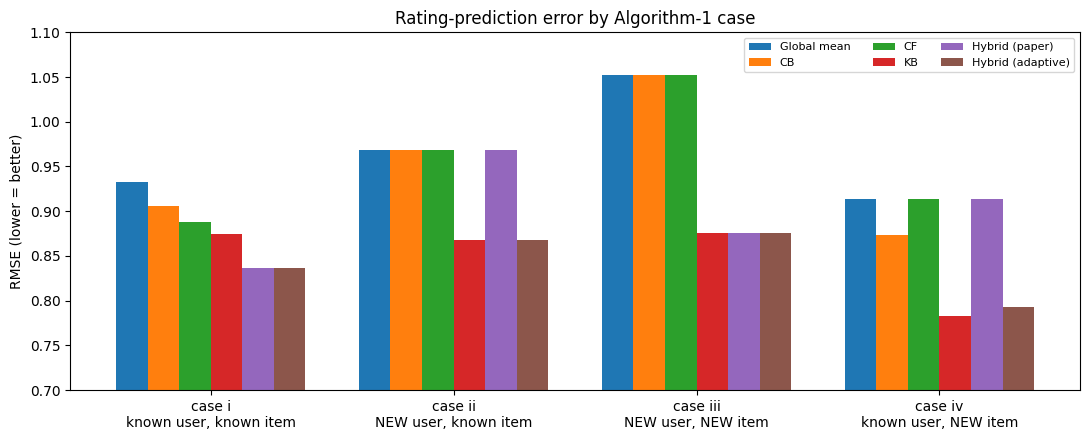

In [18]:
# Bar chart: error of each method in each of the 4 cases (shorter bar = better)
fig, ax = plt.subplots(figsize=(11, 4.5))
cols = ['RMSE case i', 'RMSE case ii', 'RMSE case iii', 'RMSE case iv']
w = 0.13                                                           # bar width
for k, n in enumerate(METHODS):
    ax.bar(np.arange(4) + (k - 2.5) * w, rating_table.loc[n, cols].values, w, label=n)
ax.set_xticks(range(4)); ax.set_xticklabels([f'case {c}\n{CASE_NAMES[c]}' for c in ['i', 'ii', 'iii', 'iv']])
ax.set_ylabel('RMSE (lower = better)'); ax.set_ylim(0.7, 1.1)
ax.set_title('Rating-prediction error by Algorithm-1 case'); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

### Relevance classification (rating ≥ 4 = "relevant") + the paper's DecisionTreeClassifier (§3.4)
For the rating-predicting methods, the "relevant" cut-off on the predicted rating is chosen on the **validation** set (maximising F1). The tree is trained on item features (category, location), the user's preference match and leave-one-out user/item averages; its depth is also chosen on validation.

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

def best_threshold(p, y):
    """Try many cut-offs and return the one where 'predicted rating >= cut-off' best matches 'truly relevant' (highest F1)."""
    cands = np.quantile(p, np.linspace(.05, .95, 37))
    return max(cands, key=lambda t: f1_score(y, p >= t, zero_division=0))

yv_bin, yt_bin = (yv >= 4).astype(int), (yt >= 4).astype(int)      # 1 = relevant (4-5 stars), 0 = not relevant
pv = pair_predictions(mod_core, uv, iv)                            # validation predictions (from the model that never saw validation)
rows = []
for n in METHODS[1:]:                                              # skip 'Global mean' (it predicts the same value for all)
    thr = best_threshold(pv[n] + 1e-9 * np.random.default_rng(0).random(len(uv)), yv_bin)   # cut-off chosen on VALIDATION
    yp = (preds[n] >= thr).astype(int)                             # apply the cut-off on the TEST set
    rows.append({'Method': n, 'Accuracy': accuracy_score(yt_bin, yp), 'Precision': precision_score(yt_bin, yp, zero_division=0),
                 'Recall': recall_score(yt_bin, yp, zero_division=0), 'F1': f1_score(yt_bin, yp, zero_division=0)})

# --- decision tree (paper 3.4) ---
def tree_xy(frame, ref, loo):
    """Build the tree's input table for `frame`. User/item average ratings come from `ref`.
    'loo' (leave-one-out) removes a row's OWN rating from its own averages so the tree cannot cheat by seeing the answer."""
    gm = ref.rating.mean()
    gu = ref.groupby('u').rating.agg(['sum', 'count']).reindex(range(nU)).fillna(0)     # per-user rating sum & count
    gi = ref.groupby('i').rating.agg(['sum', 'count']).reindex(range(nI)).fillna(0)     # per-item rating sum & count
    su, cu = gu['sum'].values[frame.u], gu['count'].values[frame.u]
    si, ci = gi['sum'].values[frame.i], gi['count'].values[frame.i]
    if loo: su, cu, si, ci = su - frame.rating.values, cu - 1, si - frame.rating.values, ci - 1
    X = pd.DataFrame(np.eye(len(CATS))[item_cat_idx[frame.i.values]], columns=CATS)      # category (one-hot)
    X['lat'], X['lon'] = item_info.lat.values[frame.i.values], item_info.lon.values[frame.i.values]   # location
    X['pref_match'] = match_mat[frame.u.values, frame.i.values]                          # does the category match the user's interests?
    X['user_mean'] = (su + 2 * gm) / (cu + 2); X['item_mean'] = (si + 5 * gm) / (ci + 5) # how generous is the user / how good is the place
    return X

depths = [3, 4, 5, 6, 8]                                           # tree depths to try (deeper = more complex)
Xc, Xv = tree_xy(train_core, train_core, True), tree_xy(val, train_core, False)
yc = (train_core.rating.values >= 4).astype(int)
# accuracy on VALIDATION for each depth -> choose the best depth
val_acc = {d: accuracy_score(yv_bin, DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=SEED).fit(Xc, yc).predict(Xv)) for d in depths}
best_depth = max(val_acc, key=val_acc.get)
# Final tree: train on all training data, evaluate ONCE on the test set
Xf, Xt = tree_xy(train_full, train_full, True), tree_xy(test, train_full, False)
tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20, random_state=SEED).fit(Xf, (train_full.rating.values >= 4).astype(int))
yp = tree.predict(Xt)
rows.append({'Method': f'DecisionTree (depth {best_depth})', 'Accuracy': accuracy_score(yt_bin, yp), 'Precision': precision_score(yt_bin, yp),
             'Recall': recall_score(yt_bin, yp), 'F1': f1_score(yt_bin, yp)})
# Baseline: a "model" that always says "not relevant". Any real method should beat its accuracy.
rows.append({'Method': 'Majority class (baseline)', 'Accuracy': 1 - yt_bin.mean(), 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0})
class_table = pd.DataFrame(rows).set_index('Method')
print('Depth chosen on validation:', best_depth, '| validation accuracies:', {d: round(a, 3) for d, a in val_acc.items()})
print('How to read this table: the cut-off is tuned for F1, so weak predictors (CB, CF) collapse to "call almost everything relevant" -> high recall but accuracy')
print('BELOW the majority-class baseline; judge them by RMSE/F1. The tree is a supervised classifier trained directly for this yes/no task on the same signals, so it')
print('wins on accuracy/precision; the hybrid is a rating predictor and wins on RMSE, recall and F1.')
class_table.round(3)

Depth chosen on validation: 4 | validation accuracies: {3: 0.674, 4: 0.678, 5: 0.645, 6: 0.664, 8: 0.656}
How to read this table: the cut-off is tuned for F1, so weak predictors (CB, CF) collapse to "call almost everything relevant" -> high recall but accuracy
BELOW the majority-class baseline; judge them by RMSE/F1. The tree is a supervised classifier trained directly for this yes/no task on the same signals, so it
wins on accuracy/precision; the hybrid is a rating predictor and wins on RMSE, recall and F1.


,Accuracy,Precision,Recall,F1
Method,,,,
CB,0.507,0.471,0.872,0.611
CF,0.512,0.475,0.936,0.630
KB,0.636,0.572,0.724,0.639
Hybrid (paper),0.594,0.576,0.330,0.419
Hybrid (adaptive),0.650,0.587,0.720,0.647
DecisionTree (depth 4),0.688,0.684,0.553,0.612
Majority class (baseline),0.556,0.000,0.000,0.000


### Top-N recommendation quality
For each test user we rank every attraction they have **not** rated in training and check how many of their held-out *relevant* (rating ≥ 4) attractions appear in the top 5 / top 10.
Absolute numbers are small because each user has only ~1 held-out relevant item — compare methods **against each other and against random**.

In [22]:
# FM = "full matrices": a score for EVERY user x attraction pair, for each method (used for ranking)
U_all, I_all = np.repeat(np.arange(nU), nI), np.tile(np.arange(nI), nU)     # every (user, item) combination
FM = {'Random': None,                                                                            # random ranking (the weakest baseline)
      'Popularity': np.tile(np.where(mod.known_i, mod.im, mod.gm), (nU, 1)),                     # same ranking for everyone: best-rated places first
      'CB': np.where(np.isnan(mod.cb), mod.gm, mod.cb), 'CF': np.where(np.isnan(mod.cf), mod.gm, mod.cf), 'KB': mod.kb,
      'Hybrid (paper)': hybrid_predict(mod, U_all, I_all, PAPER)[0].reshape(nU, nI),
      'Hybrid (adaptive)': hybrid_predict(mod, U_all, I_all, ADAPT)[0].reshape(nU, nI)}

def topn_eval(user_ok, names, K=5, K2=10):
    """For every user accepted by `user_ok`: rank the attractions they have not rated, take the top K / K2,
    and count how many of their truly relevant test attractions were found."""
    seen = train_full.groupby('u').i.apply(set).to_dict()                    # attractions each user already rated (never recommend again)
    rel = test[test.rating >= 4].groupby('u').i.apply(set).to_dict()        # each user's truly relevant test attractions
    ev = [u for u in rel if user_ok(u)]                                      # users we evaluate
    tie = np.random.default_rng(1)                                           # tiny random noise to break ties fairly
    out = []
    for n in names:
        P, R, H = [], [], []
        for u in ev:
            sc = (np.random.default_rng(u).random(nI) if n == 'Random' else FM[n][u].copy()) + 1e-6 * tie.random(nI)
            sc[list(seen.get(u, []))] = -np.inf                              # exclude already-rated attractions
            top = np.argsort(-sc)[:K2]                                       # indices of the K2 highest-scored attractions
            h5 = len(set(top[:K]) & rel[u])                                  # hits inside the top 5
            P.append(h5 / K)                                                 # Precision@5 = hits / 5
            R.append(h5 / len(rel[u]))                                       # Recall@5 = hits / all relevant items
            H.append(len(set(top) & rel[u]) > 0)                             # HitRate@10 = at least one hit in top 10?
        out.append({'Method': n, 'Precision@5': np.mean(P), 'Recall@5': np.mean(R), 'HitRate@10': np.mean(H)})
    return pd.DataFrame(out).set_index('Method'), len(ev)

warm_names = ['Random', 'Popularity', 'CB', 'CF', 'KB', 'Hybrid (paper)', 'Hybrid (adaptive)']
cold_names = ['Random', 'Popularity', 'KB', 'Hybrid (paper)', 'Hybrid (adaptive)']   # CB/CF have no data for a brand-new user
topn_warm, n_warm = topn_eval(lambda u: mod.known_u[u], warm_names)                  # users WITH history
topn_cold, n_cold = topn_eval(lambda u: not mod.known_u[u], cold_names)              # brand-new users (cold start)
print(f'WARM users (have history), n = {n_warm}'); display(topn_warm.round(3))
print(f'COLD-START users (brand new, no ratings), n = {n_cold}'); display(topn_cold.round(3))

WARM users (have history), n = 754


,Precision@5,Recall@5,HitRate@10
Method,,,
Random,0.015,0.048,0.147
Popularity,0.019,0.071,0.145
CB,0.029,0.103,0.261
CF,0.022,0.083,0.198
KB,0.038,0.134,0.408
Hybrid (paper),0.038,0.135,0.298
Hybrid (adaptive),0.046,0.163,0.410


COLD-START users (brand new, no ratings), n = 173


,Precision@5,Recall@5,HitRate@10
Method,,,
Random,0.042,0.071,0.301
Popularity,0.046,0.094,0.301
KB,0.096,0.180,0.590
Hybrid (paper),0.067,0.133,0.353
Hybrid (adaptive),0.096,0.180,0.595


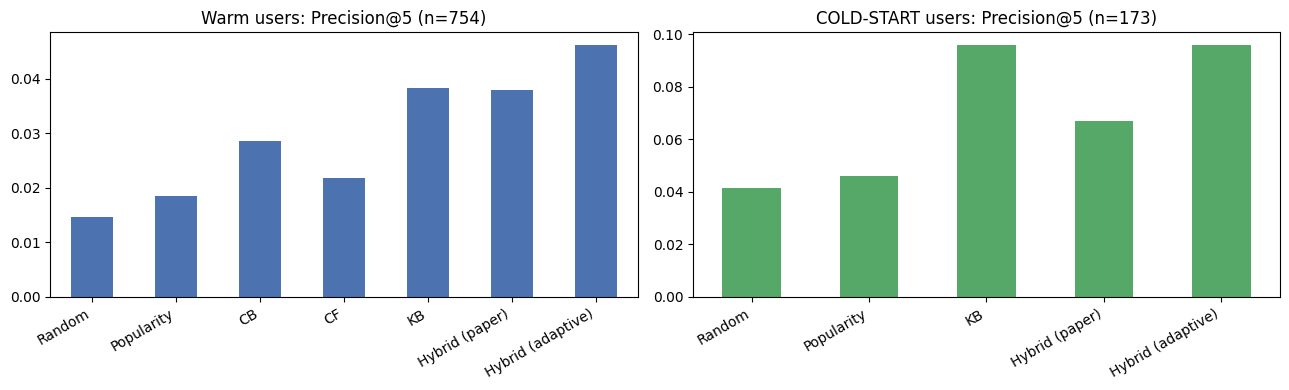

In [23]:
# Bar charts of Precision@5 (taller = better)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
topn_warm['Precision@5'].plot(kind='bar', ax=ax[0], color='#4C72B0'); ax[0].set_title(f'Warm users: Precision@5 (n={n_warm})')
topn_cold['Precision@5'].plot(kind='bar', ax=ax[1], color='#55A868'); ax[1].set_title(f'COLD-START users: Precision@5 (n={n_cold})')
for a in ax: a.set_xlabel(''); plt.setp(a.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout(); plt.show()

## Step 8 — How do our results compare with the base-paper replication?

We did not get the authors' code or dataset, so the paper's published figures are **not** used as a yardstick here. Instead we compare against our own **faithful replication of the paper's method** (`paper_replication.ipynb`: the paper's Algorithm 1 routing, user-based k-NN CF, fixed-weight CB, KB, and the paper's decision tree), run on **exactly the same dataset, seed and train/test split** as this notebook (same 3,414 test ratings).

The question is therefore simple: **does our improved version (validation-tuned CB/CF + adaptive hybrid) beat the replicated paper method on identical data?**
The replication scores relevance with a fixed cut-off of 3.5; ours tunes the cut-off for F1 on a validation set, so the table also shows ours at the **same fixed 3.5 cut-off** for a like-for-like comparison.

In [24]:
# Replication of the base paper (paper_replication.ipynb) next to ours - same data, seed and test ratings.
# Replication values come from that notebook's realistic split (relevant = rating >= 4, fixed cut-off 3.5).
repl = {'Replication — Hybrid (paper Alg. 1)': [59.6, 60.4, 26.6, 36.9],
        'Replication — Hybrid (adaptive)':     [65.9, 62.3, 58.6, 60.4],
        'Replication — DecisionTree':          [67.4, 61.1, 58.2, 59.6]}     # tree: attribute features, target = relevant (>=4)
cmp_tbl = pd.DataFrame(repl, index=['Accuracy', 'Precision', 'Recall', 'F1'])

hy = class_table.loc['Hybrid (adaptive)']; dt = class_table.loc[f'DecisionTree (depth {best_depth})']
yh35 = (np.asarray(preds['Hybrid (adaptive)'], float) >= 3.5).astype(int)          # ours at the replication's fixed cut-off
cmp_tbl['Ours — Hybrid (adaptive), cut-off 3.5'] = [accuracy_score(yt_bin, yh35) * 100, precision_score(yt_bin, yh35, zero_division=0) * 100,
                                                   recall_score(yt_bin, yh35) * 100, f1_score(yt_bin, yh35) * 100]
cmp_tbl['Ours — Hybrid (adaptive), tuned cut-off'] = [hy.Accuracy * 100, hy.Precision * 100, hy.Recall * 100, hy.F1 * 100]
cmp_tbl['Ours — DecisionTree'] = [dt.Accuracy * 100, dt.Precision * 100, dt.Recall * 100, dt.F1 * 100]
cmp_tbl['Majority baseline'] = [class_table.loc['Majority class (baseline)', 'Accuracy'] * 100, 0, 0, 0]
cmp_tbl.round(1)

,Replication — Hybrid (paper Alg. 1),Replication — Hybrid (adaptive),Replication — DecisionTree,"Ours — Hybrid (adaptive), cut-off 3.5","Ours — Hybrid (adaptive), tuned cut-off",Ours — DecisionTree,Majority baseline
Accuracy,59.6,65.9,67.4,67.2,65.0,68.8,55.6
Precision,60.4,62.3,61.1,65.5,58.7,68.4,0.0
Recall,26.6,58.6,58.2,55.0,72.0,55.3,0.0
F1,36.9,60.4,59.6,59.8,64.7,61.2,0.0


In [25]:
# Automatically written summary of the main findings (numbers are filled in from the results above)
best_single = rating_table.loc[['CB', 'CF', 'KB'], 'RMSE case i'].idxmin()
print('KEY FINDINGS')
print(f"1. Case i (known user & item): hybrid RMSE {rating_table.loc['Hybrid (adaptive)', 'RMSE case i']:.3f} vs best single module "
      f"({best_single}) {rating_table.loc[best_single, 'RMSE case i']:.3f} vs global mean {rating_table.loc['Global mean', 'RMSE case i']:.3f}  -> fusion helps.")
print(f"2. Paper's Algorithm 1 as written had NO usable module for {fb_paper.mean():.0%} of test ratings; the adaptive variant fixes this ({fb_adapt.mean():.0%}).")
print(f"3. Cold-start users, Precision@5: hybrid (adaptive) {topn_cold.loc['Hybrid (adaptive)', 'Precision@5']:.3f} vs "
      f"random {topn_cold.loc['Random', 'Precision@5']:.3f} vs popularity {topn_cold.loc['Popularity', 'Precision@5']:.3f}.")
print("   (For a brand-new user only KB has any data, so the adaptive hybrid reduces to KB here - this is exactly the paper's argument for including KB.)")
print(f"   Paper's Algorithm 1 as written reaches only {topn_cold.loc['Hybrid (paper)', 'Precision@5']:.3f} for cold users because it routes them to CB/CF, which have no data.")
print(f"4. Honest caveat: in case iv (known user, new item) KB alone ({rating_table.loc['KB', 'RMSE case iv']:.3f}) is about as good as / slightly better than "
      f"the CB+KB average ({rating_table.loc['Hybrid (adaptive)', 'RMSE case iv']:.3f}); equal weights are not always optimal.")

KEY FINDINGS
1. Case i (known user & item): hybrid RMSE 0.837 vs best single module (KB) 0.875 vs global mean 0.933  -> fusion helps.
2. Paper's Algorithm 1 as written had NO usable module for 50% of test ratings; the adaptive variant fixes this (0%).
3. Cold-start users, Precision@5: hybrid (adaptive) 0.096 vs random 0.042 vs popularity 0.046.
   (For a brand-new user only KB has any data, so the adaptive hybrid reduces to KB here - this is exactly the paper's argument for including KB.)
   Paper's Algorithm 1 as written reaches only 0.067 for cold users because it routes them to CB/CF, which have no data.
4. Honest caveat: in case iv (known user, new item) KB alone (0.783) is about as good as / slightly better than the CB+KB average (0.793); equal weights are not always optimal.


## Step 9 — Demo: get recommendations (paper §3.5 "Improved Recommendation Engine")

In [26]:
def describe(idx, scores=None):
    """Turn a list of attraction numbers into a readable table (id, city, category, predicted rating)."""
    d = pd.DataFrame({'attraction': [items[i] for i in idx], 'city': item_info.city.values[idx], 'category': item_info.cat.values[idx]})
    if scores is not None: d['predicted rating'] = np.round(scores, 2)
    return d.reset_index(drop=True)

def recommend_new_user(preferred_categories, top_n=5):
    """COLD START: a brand-new user who only filled the registration form. Uses the KB module."""
    m = np.isin(item_info.cat.values, preferred_categories).astype(float)              # 1 for attractions in the chosen categories
    score = mod.gm + np.where(mod.known_i, mod.im - mod.gm, 0.0) + mod.delta * m        # KB score = average + place quality + preference bonus
    top = np.argsort(-(score + 1e-6 * np.random.default_rng(0).random(nI)))[:top_n]     # the top_n best-scoring attractions
    return describe(top, score[top])

def recommend_existing_user(user_id, top_n=5):
    """A user WITH history: uses the adaptive hybrid (CB + CF + KB) and skips attractions the user already rated."""
    u = uix[user_id]
    sc = FM['Hybrid (adaptive)'][u].copy(); sc[train_full[train_full.u == u].i.values] = -np.inf
    top = np.argsort(-sc)[:top_n]
    return describe(top, sc[top])

# Try it! Change the category names below to see different recommendations. Valid names:
# 'Historical Landmark', 'Museum', 'Natural Wonder', 'Adventure Spot', 'Urban Landmark', 'Entertainment Venue'
print('NEW user who likes Natural Wonder + Adventure Spot:'); display(recommend_new_user(['Natural Wonder', 'Adventure Spot']))
print('NEW user who likes Museum + Historical Landmark:');   display(recommend_new_user(['Museum', 'Historical Landmark']))
demo_user = users[int(train_full.u.value_counts().index[0])]      # pick the user with the most training ratings
print(f'Existing user {demo_user}:'); display(recommend_existing_user(demo_user))

NEW user who likes Natural Wonder + Adventure Spot:


,attraction,city,category,predicted rating
0,A036,Karachi,Natural Wonder,4.37
1,A069,Chitral,Natural Wonder,4.32
2,A049,Quetta,Adventure Spot,4.30
3,A060,Skardu,Adventure Spot,4.23
4,A070,Chitral,Adventure Spot,4.19


NEW user who likes Museum + Historical Landmark:


,attraction,city,category,predicted rating
0,A010,Multan,Historical Landmark,4.58
1,A022,Bahawalpur,Museum,4.51
2,A028,Rawalpindi,Historical Landmark,4.43
3,A079,Murree,Historical Landmark,4.34
4,A051,Quetta,Museum,4.32


Existing user U0048:


,attraction,city,category,predicted rating
0,A059,Skardu,Entertainment Venue,3.71
1,A035,Islamabad,Entertainment Venue,3.63
2,A022,Bahawalpur,Museum,3.61
3,A007,Multan,Urban Landmark,3.60
4,A049,Quetta,Adventure Spot,3.58


In [31]:
# ==========================================
# INTERACTIVE TOURISM RECOMMENDATION SYSTEM
# ==========================================

def describe(idx, scores=None):
    d = pd.DataFrame({
        'Attraction': [items[i] for i in idx],
        'City': item_info.city.values[idx],
        'Category': item_info.cat.values[idx]
    })

    if scores is not None:
        d['Predicted Rating'] = np.round(scores, 2)

    return d.reset_index(drop=True)


# ------------------------------------------
# 1. NEW USER RECOMMENDATION
# ------------------------------------------

def recommend_new_user(preferred_categories, top_n=5):

    m = np.isin(
        item_info.cat.values,
        preferred_categories
    ).astype(float)

    score = (
        mod.gm
        + np.where(mod.known_i, mod.im - mod.gm, 0.0)
        + mod.delta * m
    )

    top = np.argsort(
        -(score + 1e-6 * np.random.default_rng(0).random(nI))
    )[:top_n]

    return describe(top, score[top])


# ------------------------------------------
# 2. EXISTING USER RECOMMENDATION
# ------------------------------------------

def recommend_existing_user(user_id, top_n=5):

    u = uix[user_id]

    sc = FM['Hybrid (adaptive)'][u].copy()

    # Remove attractions already rated
    rated_items = train_full[train_full.u == u].i.values
    sc[rated_items] = -np.inf

    top = np.argsort(-sc)[:top_n]

    return describe(top, sc[top])


# ------------------------------------------
# 3. GET INPUT FROM USER
# ------------------------------------------

print("====================================")
print("   TOURISM RECOMMENDATION SYSTEM")
print("====================================")

print("\n1. New User")
print("2. Existing User")

choice = input("\nEnter your choice (1 or 2): ").strip()

try:
    top_n = int(input("\nHow many recommendations do you want? "))

    if top_n < 1 or top_n > nI:
        print("Please enter a valid number of recommendations.")

    elif choice == '1':

        print("\nAvailable Categories:")

        categories = [
            'Historical Landmark',
            'Museum',
            'Natural Wonder',
            'Adventure Spot',
            'Urban Landmark',
            'Entertainment Venue'
        ]

        for i, category in enumerate(categories, 1):
            print(f"{i}. {category}")

        user_input = input(
            "\nEnter your preferred categories separated by commas: "
        )

        category_map = {c.lower(): c for c in categories}

        preferences = [
            category_map[x.strip().lower()]
            for x in user_input.split(',')
            if x.strip().lower() in category_map
        ]

        # Remove duplicate preferences
        preferences = list(dict.fromkeys(preferences))

        if not preferences:
            print("Invalid categories. Please try again.")

        else:
            print("\nYour Selected Preferences:", preferences)

            print("\nRECOMMENDED TOURIST ATTRACTIONS")

            display(recommend_new_user(preferences, top_n))


    elif choice == '2':

        print("\nAvailable User IDs (Sample):")
        print(list(uix.keys())[:10])

        user_id = input("\nEnter your User ID: ").strip().upper()

        # Accept both 1216 and U1216
        if user_id.isdigit():
            user_id = "U" + user_id.zfill(4)

        if user_id not in uix:
            print("Invalid User ID. Please enter a valid ID.")

        elif uix[user_id] not in set(train_full.u):
            print("This user has no training rating history.")

        else:
            print("\nGenerating personalized recommendations...")

            print("\nRECOMMENDED TOURIST ATTRACTIONS")

            display(recommend_existing_user(user_id, top_n))


    else:
        print("Invalid choice. Please select 1 or 2.")


except ValueError:
    print("Invalid input. Please enter a valid number.")



   TOURISM RECOMMENDATION SYSTEM

1. New User
2. Existing User

Enter your choice (1 or 2): 2

How many recommendations do you want? 10

Available User IDs (Sample):
['U0001', 'U0002', 'U0003', 'U0004', 'U0005', 'U0006', 'U0007', 'U0008', 'U0009', 'U0010']

Enter your User ID: U1546

Generating personalized recommendations...

RECOMMENDED TOURIST ATTRACTIONS


,Attraction,City,Category,Predicted Rating
0,A010,Multan,Historical Landmark,3.42
1,A059,Skardu,Entertainment Venue,3.40
2,A022,Bahawalpur,Museum,3.40
3,A007,Multan,Urban Landmark,3.39
4,A028,Rawalpindi,Historical Landmark,3.33
5,A035,Islamabad,Entertainment Venue,3.32
6,A039,Karachi,Entertainment Venue,3.29
7,A052,Quetta,Urban Landmark,3.27
8,A079,Murree,Historical Landmark,3.26
9,A049,Quetta,Adventure Spot,3.26


In [32]:
# ==========================================
# INTERACTIVE TOURISM RECOMMENDATION SYSTEM
# ==========================================

def describe(idx, scores=None):
    d = pd.DataFrame({
        'Attraction': [items[i] for i in idx],
        'City': item_info.city.values[idx],
        'Category': item_info.cat.values[idx]
    })

    if scores is not None:
        d['Predicted Rating'] = np.round(scores, 2)

    return d.reset_index(drop=True)


# ------------------------------------------
# 1. NEW USER RECOMMENDATION
# ------------------------------------------

def recommend_new_user(preferred_categories, top_n=5):

    m = np.isin(
        item_info.cat.values,
        preferred_categories
    ).astype(float)

    score = (
        mod.gm
        + np.where(mod.known_i, mod.im - mod.gm, 0.0)
        + mod.delta * m
    )

    top = np.argsort(
        -(score + 1e-6 * np.random.default_rng(0).random(nI))
    )[:top_n]

    return describe(top, score[top])


# ------------------------------------------
# 2. EXISTING USER RECOMMENDATION
# ------------------------------------------

def recommend_existing_user(user_id, top_n=5):

    u = uix[user_id]

    sc = FM['Hybrid (adaptive)'][u].copy()

    # Remove attractions already rated
    rated_items = train_full[train_full.u == u].i.values
    sc[rated_items] = -np.inf

    top = np.argsort(-sc)[:top_n]

    return describe(top, sc[top])


# ------------------------------------------
# 3. GET INPUT FROM USER
# ------------------------------------------

print("====================================")
print("   TOURISM RECOMMENDATION SYSTEM")
print("====================================")

print("\n1. New User")
print("2. Existing User")

choice = input("\nEnter your choice (1 or 2): ").strip()

try:
    top_n = int(input("\nHow many recommendations do you want? "))

    if top_n < 1 or top_n > nI:
        print("Please enter a valid number of recommendations.")

    elif choice == '1':

        print("\nAvailable Categories:")

        categories = [
            'Historical Landmark',
            'Museum',
            'Natural Wonder',
            'Adventure Spot',
            'Urban Landmark',
            'Entertainment Venue'
        ]

        for i, category in enumerate(categories, 1):
            print(f"{i}. {category}")

        user_input = input(
            "\nEnter your preferred categories separated by commas: "
        )

        category_map = {c.lower(): c for c in categories}

        preferences = [
            category_map[x.strip().lower()]
            for x in user_input.split(',')
            if x.strip().lower() in category_map
        ]

        # Remove duplicate preferences
        preferences = list(dict.fromkeys(preferences))

        if not preferences:
            print("Invalid categories. Please try again.")

        else:
            print("\nYour Selected Preferences:", preferences)

            print("\nRECOMMENDED TOURIST ATTRACTIONS")

            display(recommend_new_user(preferences, top_n))


    elif choice == '2':

        print("\nAvailable User IDs (Sample):")
        print(list(uix.keys())[:10])

        user_id = input("\nEnter your User ID: ").strip().upper()

        # Accept both 1216 and U1216
        if user_id.isdigit():
            user_id = "U" + user_id.zfill(4)

        if user_id not in uix:
            print("Invalid User ID. Please enter a valid ID.")

        elif uix[user_id] not in set(train_full.u):
            print("This user has no training rating history.")

        else:
            print("\nGenerating personalized recommendations...")

            print("\nRECOMMENDED TOURIST ATTRACTIONS")

            display(recommend_existing_user(user_id, top_n))


    else:
        print("Invalid choice. Please select 1 or 2.")


except ValueError:
    print("Invalid input. Please enter a valid number.")



   TOURISM RECOMMENDATION SYSTEM

1. New User
2. Existing User

Enter your choice (1 or 2): 1

How many recommendations do you want? 10

Available Categories:
1. Historical Landmark
2. Museum
3. Natural Wonder
4. Adventure Spot
5. Urban Landmark
6. Entertainment Venue

Enter your preferred categories separated by commas: Museum,Natural Wonder,Historical Landmark

Your Selected Preferences: ['Museum', 'Natural Wonder', 'Historical Landmark']

RECOMMENDED TOURIST ATTRACTIONS


,Attraction,City,Category,Predicted Rating
0,A010,Multan,Historical Landmark,4.58
1,A022,Bahawalpur,Museum,4.51
2,A028,Rawalpindi,Historical Landmark,4.43
3,A036,Karachi,Natural Wonder,4.37
4,A079,Murree,Historical Landmark,4.34
5,A051,Quetta,Museum,4.32
6,A005,Lahore,Museum,4.32
7,A069,Chitral,Natural Wonder,4.32
8,A016,Peshawar,Historical Landmark,4.30
9,A012,Taxila,Historical Landmark,4.29
